Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [2]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy
import json
from ipywidgets import interactive
import math

import matplotlib.animation
from IPython.display import HTML

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCost
from Components.Controllers import TimeVaryingCost_LQRc_RHG, LQRc_welfare
from Components.Solver import fbrs

In [206]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Parameters heterogeneity

## Pumping weight difference (Electricity)

In [207]:
final_costs = {'game': [], 'welfare': []}

#### Similar electricity prices

In [208]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-120244/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-120118/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51892/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


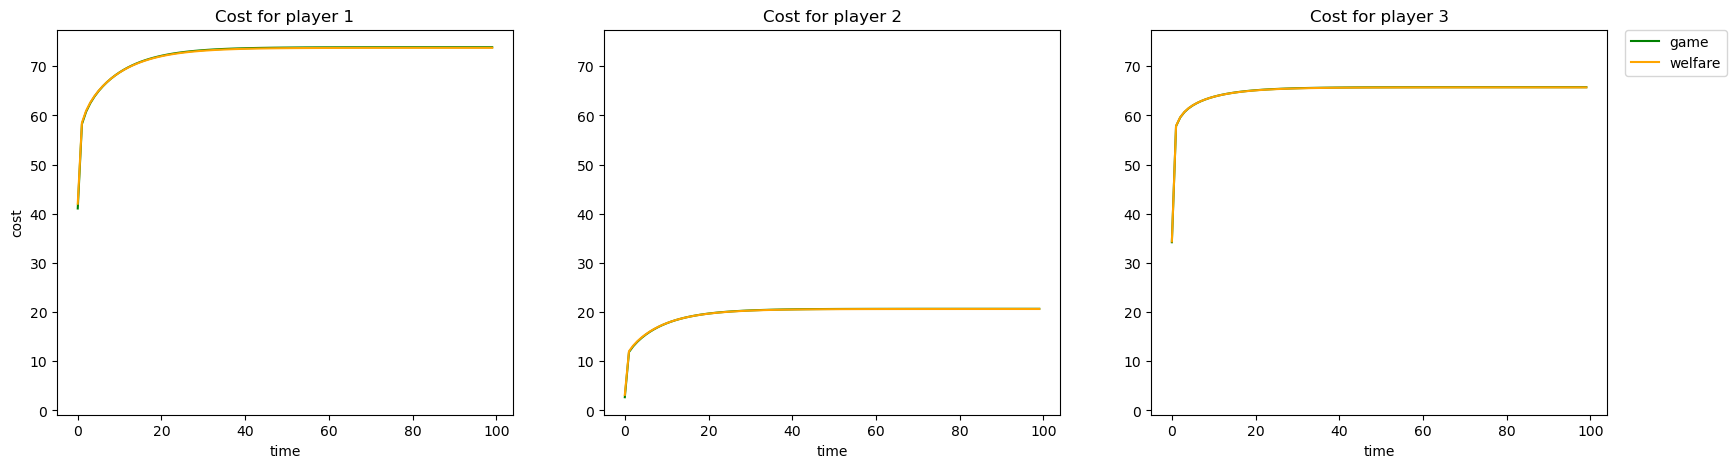

In [209]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51892/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


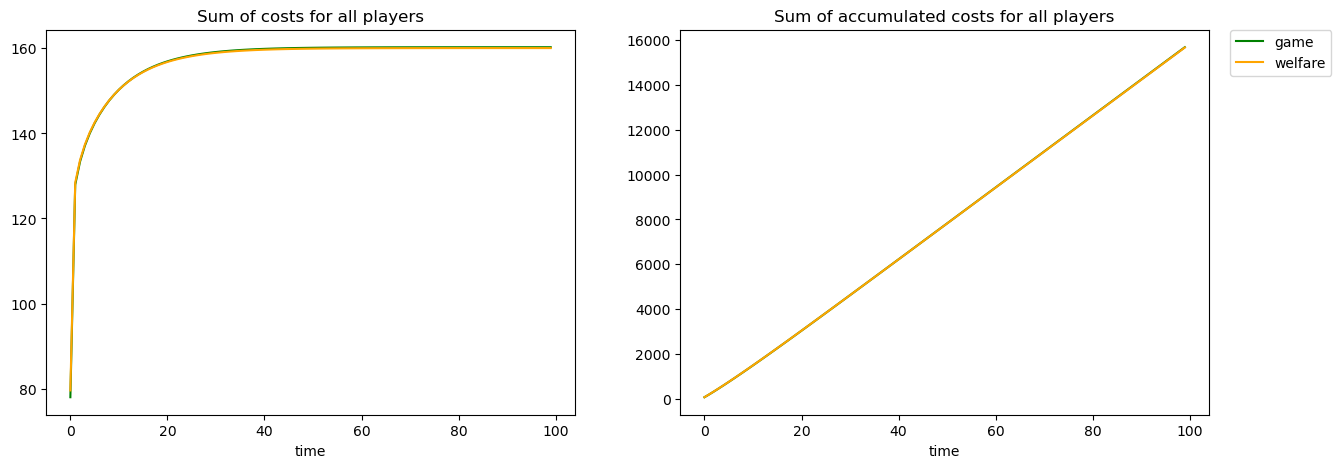

In [210]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

In [211]:
final_costs['game'].append(-data_si['model_profit'].sum())
final_costs['welfare'].append(-data_wf['model_profit'].sum())

#### Electricity prices 100x higher for player 1

In [212]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-122026/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-122153/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51892/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


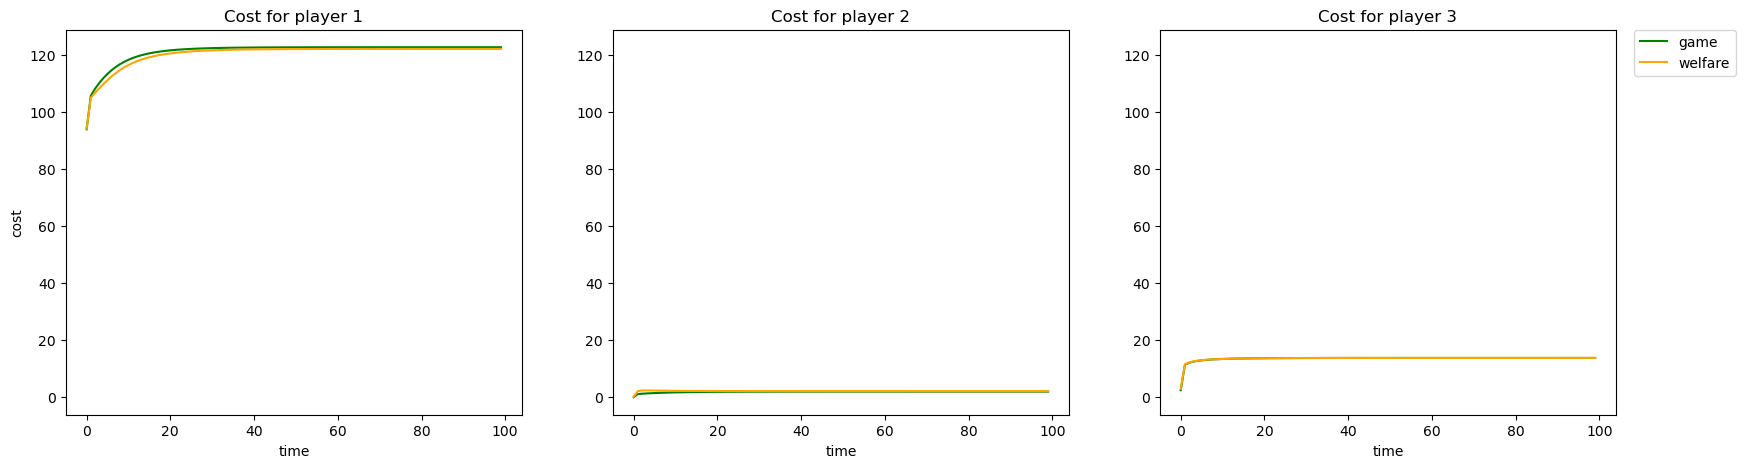

In [213]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51892/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


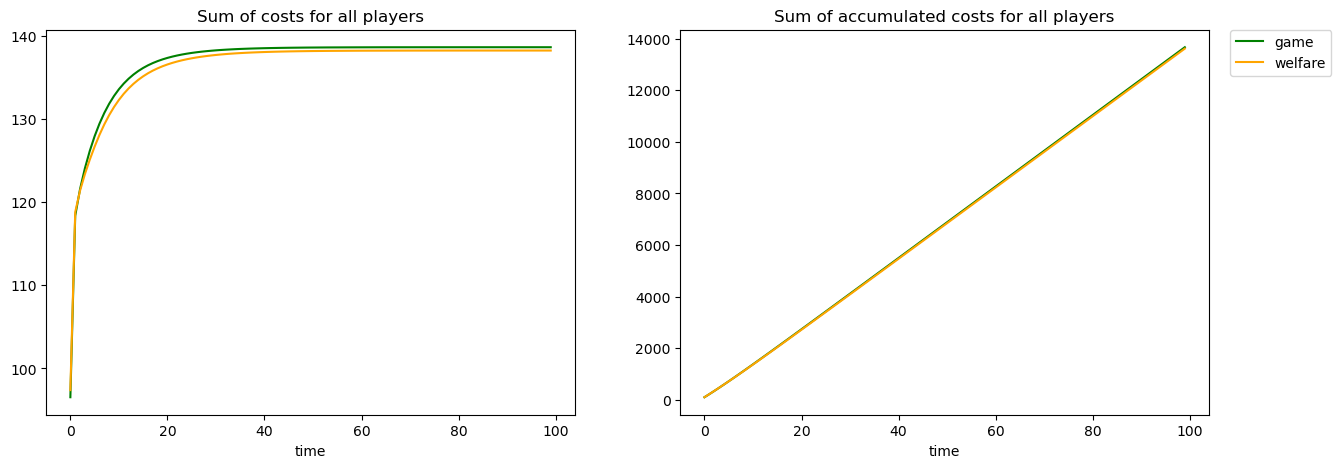

In [214]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

In [215]:
final_costs['game'].append(-data_si['model_profit'].sum())
final_costs['welfare'].append(-data_wf['model_profit'].sum())

#### Electricity price 100x higher for player 2 who is also very sensible to yield and has less land

Player 1: small electricity prices, little sensibility to yield and high demand

Player 2: high sensibility, lower demand

In [216]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144748/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144617/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51892/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


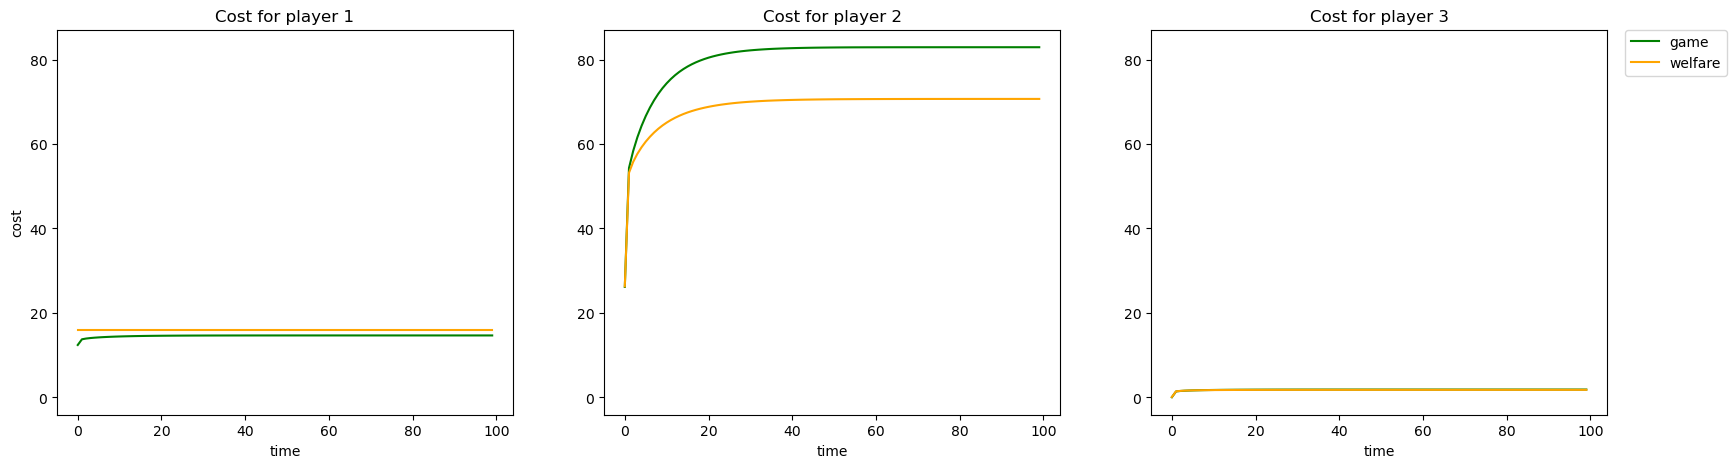

In [217]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51892/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


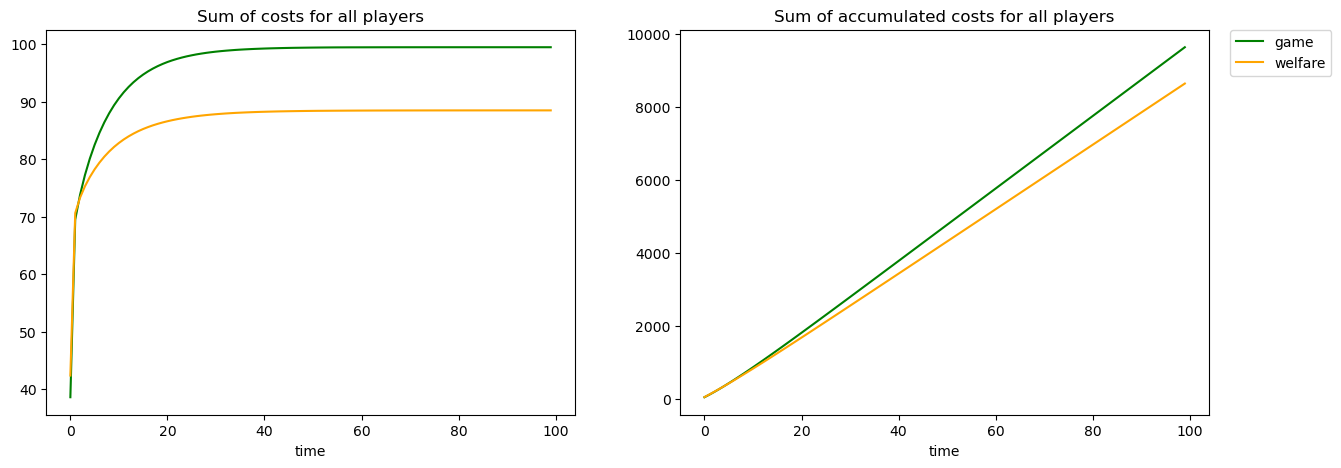

In [218]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

In [219]:
np.cumsum(data_wf['model_profit'].sum(axis=0))[-1] - np.cumsum(data_si['model_profit'].sum(axis=0))[-1], (np.cumsum(data_wf['model_profit'].sum(axis=0))[-1] - np.cumsum(data_si['model_profit'].sum(axis=0))[-1])/np.cumsum(data_wf['model_profit'].sum(axis=0))[-1]

(np.float64(996.9717266792177), np.float64(-0.11528741990864301))

In [220]:
final_costs['game'].append(-data_si['model_profit'].sum())
final_costs['welfare'].append(-data_wf['model_profit'].sum())

##### Effect amplification

Increase yield sensitivity of player 2

In [221]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-150617/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-150456/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51892/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


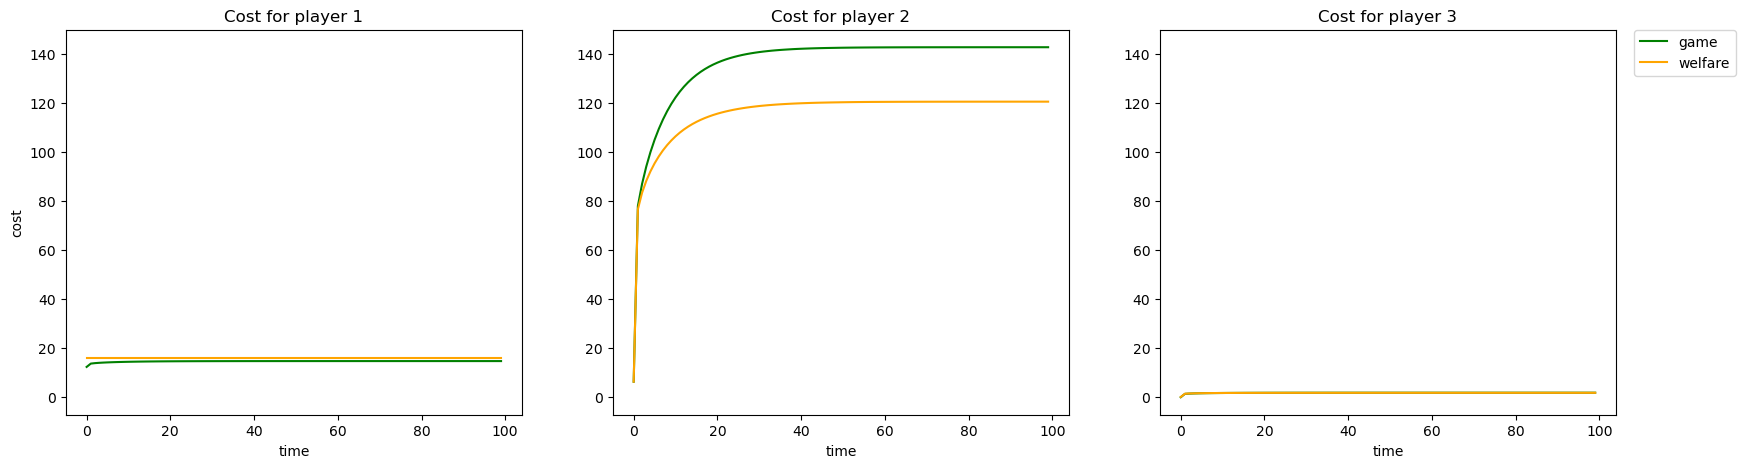

In [222]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51892/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


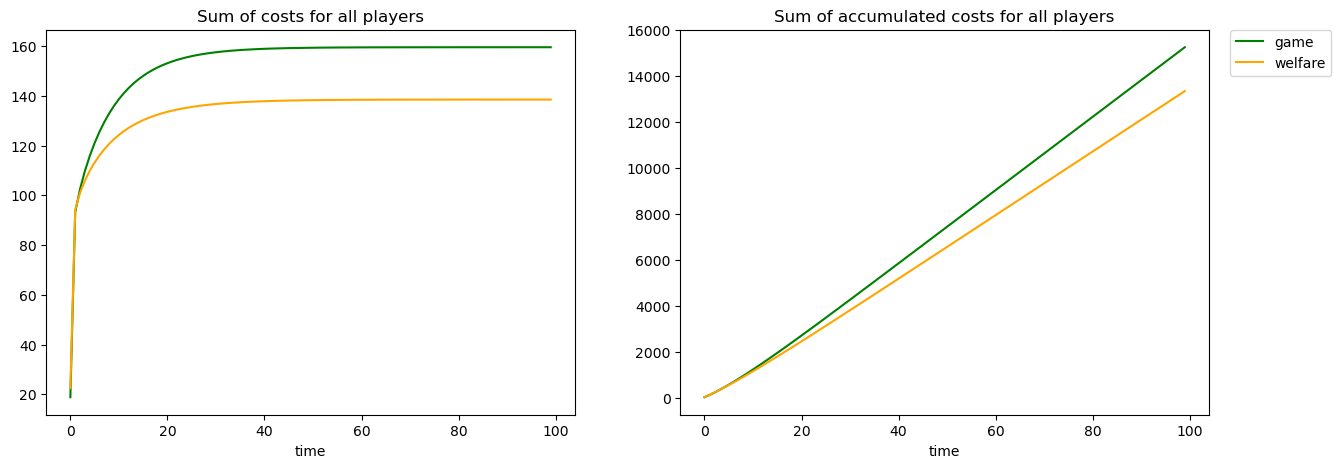

In [223]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

In [224]:
final_costs['game'].append(-data_si['model_profit'].sum())
final_costs['welfare'].append(-data_wf['model_profit'].sum())

In [225]:
np.cumsum(data_wf['model_profit'].sum(axis=0))[-1] - np.cumsum(data_si['model_profit'].sum(axis=0))[-1], (np.cumsum(data_wf['model_profit'].sum(axis=0))[-1] - np.cumsum(data_si['model_profit'].sum(axis=0))[-1])/np.cumsum(data_wf['model_profit'].sum(axis=0))[-1]

(np.float64(1909.683953077676), np.float64(-0.1430653317060164))

In [226]:
data_wf['model_profit'].sum(axis=0)[-1] - data_si['model_profit'].sum(axis=0)[-1], (data_wf['model_profit'].sum(axis=0)[-1] - data_si['model_profit'].sum(axis=0)[-1])/data_wf['model_profit'].sum(axis=0)[-1]

(np.float64(21.046261763382688), np.float64(-0.15193471804963676))

In [227]:
[data_wf['model_profit'][ii,-1] - data_si['model_profit'][ii,-1] for ii in range(3)], [(data_wf['model_profit'][ii,-1] - data_si['model_profit'][ii,-1])/data_wf['model_profit'][ii,-1] for ii in range(3)]

([np.float64(-1.207270759439167),
  np.float64(22.213349954953742),
  np.float64(0.04018256786814334)],
 [np.float64(0.07545442246494799),
  np.float64(-0.18407548219099937),
  np.float64(-0.021761263303116493)])

##### Remark

Looking at the equation we realize that:
- the elements of the linear part of the under-irrigation cost are proportional with the yield sensitivity and inversely proportional with the land size
- the elements of the quadratic part of the under-irrigation cost are proportional with yield sensitivity and inversely proportional with the square of the land size

So:
- increasing land size increase the zero-crossing of the gradient and decrease it's slope
- increasing yield sensitivity increase slope without changing zero-crossing

This means that, if we don't change the pumping cost, the same optimal pumping rate with decreased sensibility can be obtained by increasing land size and increasing yield sensitivity. The under-irrigation gradient slope will be smaller iff $\left(\frac{Land'}{Land}\right)^2 \ge \frac{Sensitivity'}{Sensitivity}$.

### Conclusion

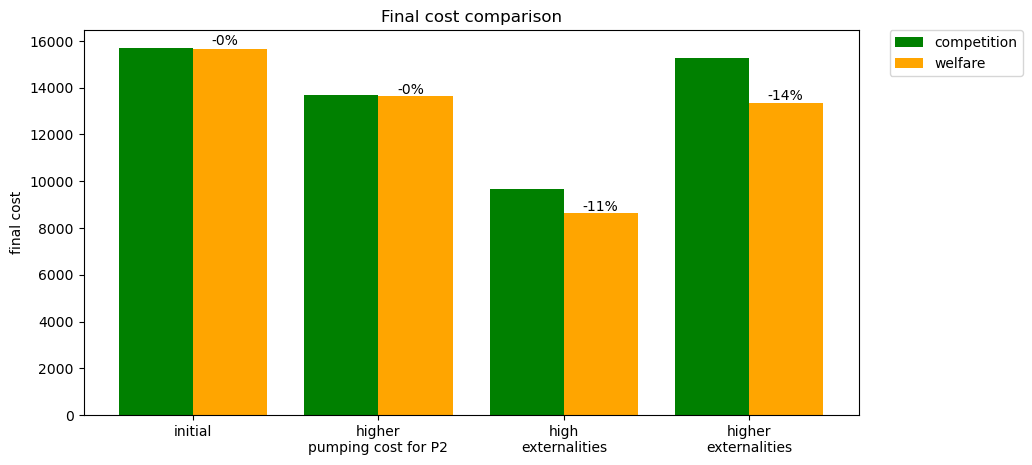

In [228]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 1, 1)
ttl = f"Final cost comparison"
ax.set_title(ttl)
ax.set_ylabel("final cost")
rects = ax.bar(np.arange(len(final_costs['game'])), final_costs['game'], width=0.40, color='g', label="competition")
rects = ax.bar(np.arange(len(final_costs['welfare']))+0.40, final_costs['welfare'], width=0.40, color='orange', label="welfare")
ax.set_xticks(np.arange(len(final_costs['game']))+0.2, ['initial', 'higher\npumping cost for P2', 'high\nexternalities', 'higher\nexternalities'])
for i, v in enumerate(final_costs['welfare']):
    plt.text(i+0.30, 1.01*v, '-'+str(int(100*(final_costs['game'][i]-v)/v))+'%')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

## Demand variation

We can vary the demand of player 1 by increasing and decreasing the amount of land that he must irrigate. We keep the sensibility to crop irrigation by enforcing: $\left(\frac{Land'}{Land}\right)^2 = \frac{Sensitivity'}{Sensitivity}$

In [ ]:
final_costs = {'game': [], 'welfare': []}

#### Baseline: situation 3 from previous study

Remark: we reduced the simulation time.

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-100106/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-100106/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

#### Multiply demand by 2

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-161641/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-161641/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

#### Multiply demand by 10

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-163717/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-163717/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

#### Divide demand by 2

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-165739/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-165739/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

#### Divide demand by 10

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-171814/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-171814/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

### Conclusion

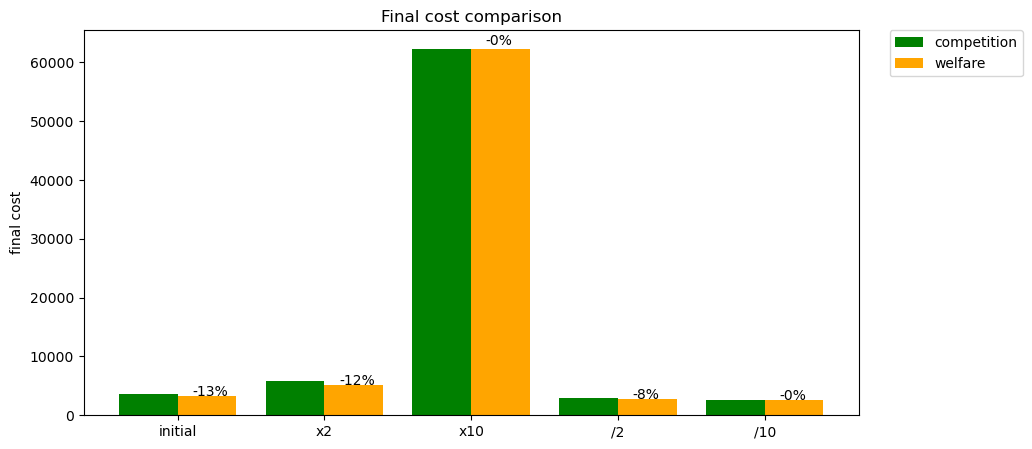

In [ ]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 1, 1)
ttl = f"Final cost comparison"
ax.set_title(ttl)
ax.set_ylabel("final cost")
rects = ax.bar(np.arange(len(final_costs['game'])), final_costs['game'], width=0.40, color='g', label="competition")
rects = ax.bar(np.arange(len(final_costs['welfare']))+0.40, final_costs['welfare'], width=0.40, color='orange', label="welfare")
ax.set_xticks(np.arange(len(final_costs['game']))+0.2, ['initial', 'x2', 'x10', '/2', '/10'])
for i, v in enumerate(final_costs['welfare']):
    plt.text(i+0.30, 1.01*v, '-'+str(int(100*(final_costs['game'][i]-v)/v))+'%')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Well position

## Bring well of player 2 closer to well of player 1

In [ ]:
field = np.zeros((25, 25))

field[12, 12] = 1
field[10, 12] = 2
field[14, 12] = 3

fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(1, 3, 1)
ax.imshow(field)

field[10, 12] = 0
field[14, 12] = 0
field[11, 12] = 2
field[13, 12] = 3

ax = fig.add_subplot(1, 3, 2)
ax.imshow(field)

field[13, 12] = 0
field[15, 12] = 3

ax = fig.add_subplot(1, 3, 3)
ax.imshow(field)

In [ ]:
final_costs = {'game': [], 'welfare': []}

#### Baseline: situation 3 from previous study

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-100106/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-100106/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

#### Diagonal Cell

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250721-104454/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250721-104454/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

#### Next Cell

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250721-110539/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250721-110539/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

### Conclusion

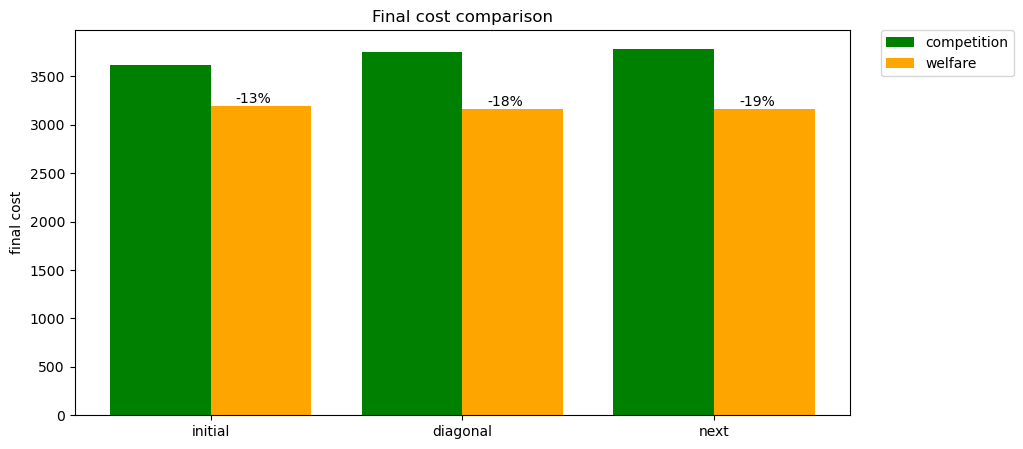

In [ ]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 1, 1)
ttl = f"Final cost comparison"
ax.set_title(ttl)
ax.set_ylabel("final cost")
rects = ax.bar(np.arange(len(final_costs['game'])), final_costs['game'], width=0.40, color='g', label="competition")
rects = ax.bar(np.arange(len(final_costs['welfare']))+0.40, final_costs['welfare'], width=0.40, color='orange', label="welfare")
ax.set_xticks(np.arange(len(final_costs['game']))+0.2, ['initial', 'diagonal', 'next'])
for i, v in enumerate(final_costs['welfare']):
    plt.text(i+0.30, 1.01*v, '-'+str(int(100*(final_costs['game'][i]-v)/v))+'%')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

## Vary number of wells of player 1 as well as distance between players' well

In [ ]:
final_costs = {'game': [], 'welfare': []}

#### Baseline (situation 3 from first study): close extra well, large distance

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-100106/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-100106/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

#### Close extra well, small distance

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250721-110539/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250721-110539/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

#### No extra well, large distance

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-204015/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-204015/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

#### No extra well, small distance

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250721-112821/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250721-112821/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

#### Distant extra well, large distance

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-174358/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250720-174358/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

#### Distant extra well, small distance

In [ ]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250721-114905/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/well_distance_study/run_20250721-114905/welfare/result_data.npz')

In [ ]:
final_costs['game'].append(-data_si['model_profit'][:2,:].sum())
final_costs['welfare'].append(-data_wf['model_profit'][:2,:].sum())

### Conclusion

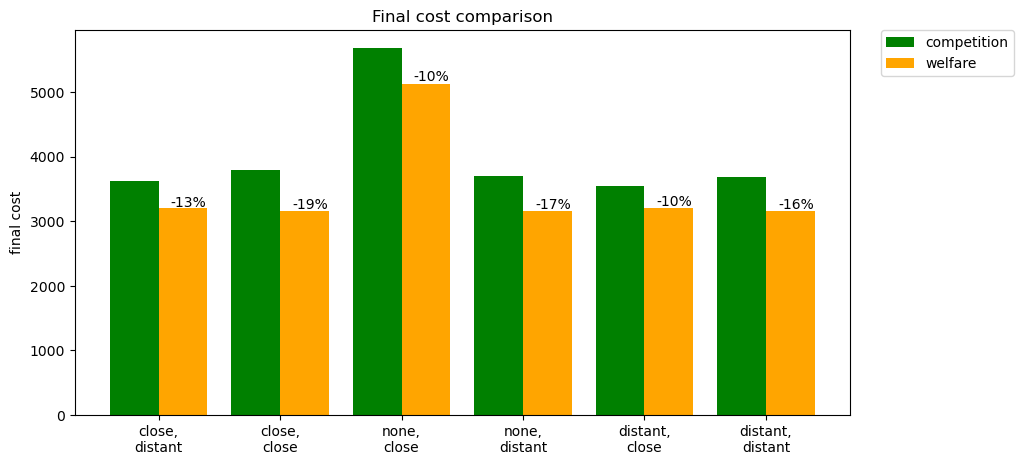

In [ ]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 1, 1)
ttl = f"Final cost comparison"
ax.set_title(ttl)
ax.set_ylabel("final cost")
rects = ax.bar(np.arange(len(final_costs['game'])), final_costs['game'], width=0.40, color='g', label="competition")
rects = ax.bar(np.arange(len(final_costs['welfare']))+0.40, final_costs['welfare'], width=0.40, color='orange', label="welfare")
ax.set_xticks(np.arange(len(final_costs['game']))+0.2, ['close,\ndistant', 'close,\nclose', 'none,\nclose', 'none,\ndistant', 'distant,\nclose','distant,\ndistant'])
for i, v in enumerate(final_costs['welfare']):
    plt.text(i+0.30, 1.01*v, '-'+str(int(100*(final_costs['game'][i]-v)/v))+'%')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Three aligned wells situation

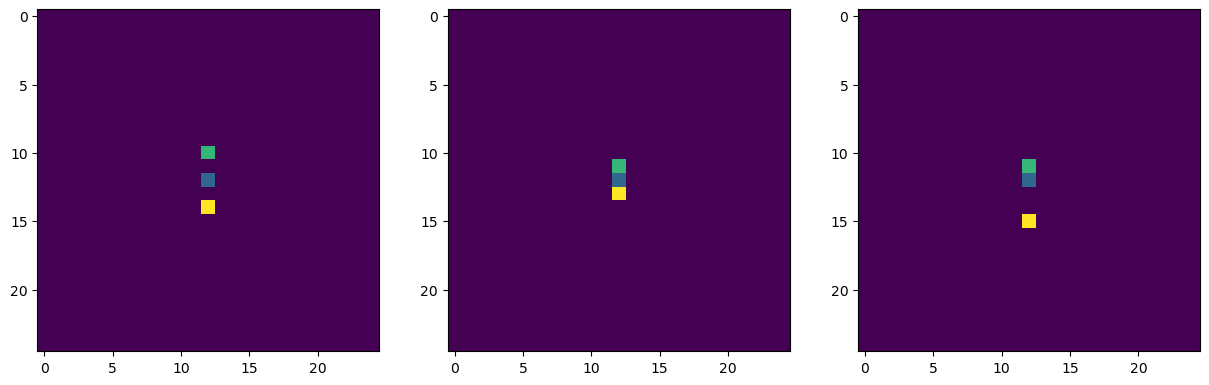

In [ ]:
field = np.zeros((25, 25))

field[12, 12] = 1
field[10, 12] = 2
field[14, 12] = 3

fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(1, 3, 1)
ax.imshow(field)

field[10, 12] = 0
field[14, 12] = 0
field[11, 12] = 2
field[13, 12] = 3

ax = fig.add_subplot(1, 3, 2)
ax.imshow(field)

field[13, 12] = 0
field[15, 12] = 3

ax = fig.add_subplot(1, 3, 3)
ax.imshow(field)

In [197]:
final_costs = {'game': [], 'welfare': []}

#### Case 1

In [198]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/aligned_wells_study/run_20250721-121627/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/aligned_wells_study/run_20250721-121627/welfare/result_data.npz')

In [199]:
final_costs['game'].append(-data_si['model_profit'].sum())
final_costs['welfare'].append(-data_wf['model_profit'].sum())

#### Case 2

In [200]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/aligned_wells_study/run_20250721-123553/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/aligned_wells_study/run_20250721-123553/welfare/result_data.npz')

In [201]:
final_costs['game'].append(-data_si['model_profit'].sum())
final_costs['welfare'].append(-data_wf['model_profit'].sum())

#### Case 3

In [202]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/aligned_wells_study/run_20250721-125350/game/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/aligned_wells_study/run_20250721-125350/welfare/result_data.npz')

In [203]:
final_costs['game'].append(-data_si['model_profit'].sum())
final_costs['welfare'].append(-data_wf['model_profit'].sum())

### Conclusion

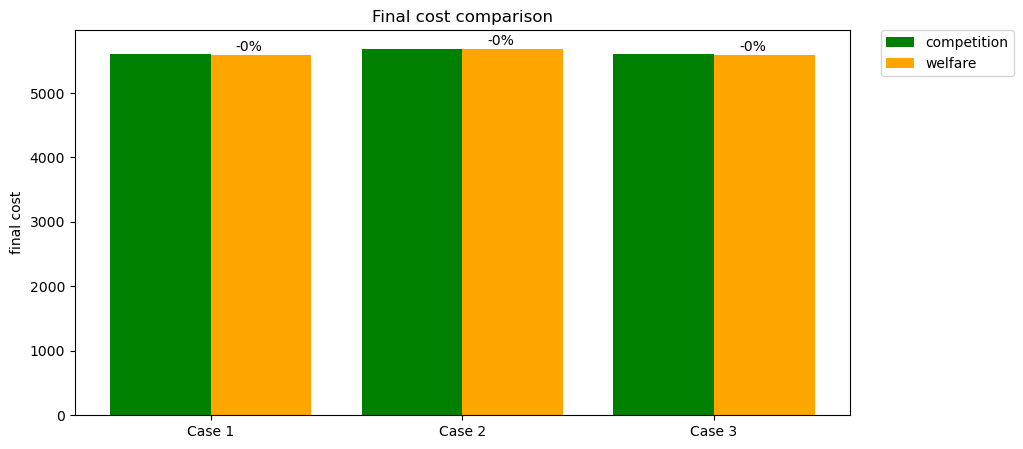

In [204]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 1, 1)
ttl = f"Final cost comparison"
ax.set_title(ttl)
ax.set_ylabel("final cost")
rects = ax.bar(np.arange(len(final_costs['game'])), final_costs['game'], width=0.40, color='g', label="competition")
rects = ax.bar(np.arange(len(final_costs['welfare']))+0.40, final_costs['welfare'], width=0.40, color='orange', label="welfare")
ax.set_xticks(np.arange(len(final_costs['game']))+0.2, ['Case 1', 'Case 2', 'Case 3'])
for i, v in enumerate(final_costs['welfare']):
    plt.text(i+0.30, 1.01*v, '-'+str(int(100*(final_costs['game'][i]-v)/v))+'%')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)